# Integration of Code Quality Features to Estimate LLM Confidence
The datasets: `all_lines_rf_dataset_with_sim` and `all_lines_rf_dataset_no_sim` aims to provide line-related features and to help predict the model confidence. The datasets have the following features (the only difference being the similarity ones between these two): 
<!-- - title -->
- line_row
- any_fix_available
- all_fixes_available
- fix_availability_ratio
- unsafe_fixes
- safe_fixes
- avg_fix_complexity
- max_fix_complexity
- min_fix_complexity
- sum_fix_complexity
- unique_issue_types
- issues_per_line
- A001, ANN001, ANN202, ANN204, ARG001, B007, B905, C901, COM812, D101, D102, D107, E226, E271, E301, E302, E305, E306, E402, E501, E741, F821, F841, I001, N803, N806, PERF401, PLC0415, PLC1901, PLR0913, PLR0914, PLR0917, PLR1730, PLR2004, PLR6104, PLW0603, PLW2901, Q000, RET504, RET505, RET507, RET508, RUF059, SIM110, W291, W292
- class, for, function, if, while
- characters_number
- similarity_2, similarity_3, similarity_4, similarity_5

In [66]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from sklearn.metrics import f1_score, make_scorer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

## Data Analysis

In [31]:
rf_dataset_sim = pd.read_csv('datasets/all_lines_rf_dataset_with_sim.csv')
rf_dataset_sim['all_fixes_available'] = rf_dataset_sim['all_fixes_available'].map(lambda x: 1 if x else 0)
rf_dataset_sim['any_fix_available'] = rf_dataset_sim['any_fix_available'].map(lambda x: 1 if x else 0)
rf_dataset_sim.head(20)

,title,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,...,class,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5
0,A+BAgain?,1,0,0,0.0,0,0,0.0,0.0,0.0,...,0,0,0,0,0,14,0.898168,0.849335,0.858385,0.862048
1,A+BAgain?,2,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,15,0.769206,0.735990,0.821829,0.860018
2,A+BAgain?,3,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,14,0.932981,0.804449,0.845420,0.874074
3,A+BAgain?,4,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,16,0.772575,0.777754,0.831880,0.856383
4,A+BAgain?,5,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,16,0.817759,0.815602,0.854043,0.862512
5,A+BAgain?,6,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,36,0.846163,0.812537,0.853950,0.877656
6,A+BAgain?,7,1,1,1.0,0,1,1.0,1.0,1.0,...,0,1,0,0,0,20,0.711183,0.802041,0.847674,0.867020
7,A.WayTooLongWords,1,0,0,0.0,0,0,NaN,NaN,NaN,...,0,0,1,0,0,20,1.000000,0.916184,0.874611,0.888081
8,A.WayTooLongWords,2,0,0,0.0,0,0,NaN,NaN,NaN,...,0,0,1,1,0,15,1.000000,0.912008,0.893955,0.915207
9,A.WayTooLongWords,3,0,0,0.0,0,0,0.0,0.0,0.0,...,0,0,1,1,0,20,1.000000,0.942011,0.924392,0.939393


In [22]:
print(f'There are {rf_dataset_sim.shape[0]} rows and {rf_dataset_sim.shape[1]} columns, excluding the target feature.')

There are 1160 rows and 69 columns, excluding the target feature.


### Missing Data Examination

In [42]:
missing_values = rf_dataset_sim.isnull().sum()
missing_values[missing_values > 0]

avg_fix_complexity     74
max_fix_complexity     74
min_fix_complexity     74
A001                  899
dtype: int64

For these missing values, it is reasonable to replace the NaNs with 0, as a value of 0 appropriately indicates that no fixes or issues were found.

In [43]:
rf_dataset_sim['avg_fix_complexity'] = rf_dataset_sim['avg_fix_complexity'].fillna(0)
rf_dataset_sim['max_fix_complexity'] = rf_dataset_sim['max_fix_complexity'].fillna(0)
rf_dataset_sim['min_fix_complexity'] = rf_dataset_sim['min_fix_complexity'].fillna(0)
rf_dataset_sim['A001'] = rf_dataset_sim['A001'].fillna(0)
rf_dataset_sim.isnull().values.any()

False

In [44]:
rf_dataset_sim.head()

,title,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,...,class,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5
0,A+BAgain?,1,0,0,0.0,0,0,0.0,0.0,0.0,...,0,0,0,0,0,14,0.898168,0.849335,0.858385,0.862048
1,A+BAgain?,2,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,15,0.769206,0.735990,0.821829,0.860018
2,A+BAgain?,3,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,14,0.932981,0.804449,0.845420,0.874074
3,A+BAgain?,4,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,16,0.772575,0.777754,0.831880,0.856383
4,A+BAgain?,5,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,0,0,0,16,0.817759,0.815602,0.854043,0.862512


### Categorical Features
All categorical features (issues_array, blocks, any_fix_available, all_fixes_available) have already been encoded using binary or one-hot encoding.

In [23]:
rf_dataset_sim['any_fix_available'].value_counts(normalize=True) * 100

any_fix_available
0    83.87931
1    16.12069
Name: proportion, dtype: float64

In [24]:
rf_dataset_sim['all_fixes_available'].value_counts(normalize=True) * 100

all_fixes_available
0    88.017241
1    11.982759
Name: proportion, dtype: float64

For more stats about the categorical features - `stats.ipynb`

### Continous Features

In [46]:
continuous_variables = rf_dataset_sim[['line_row', 'unsafe_fixes', 'safe_fixes', 'avg_fix_complexity', 'max_fix_complexity', 'min_fix_complexity', 'sum_fix_complexity', 'unique_issue_types', 'issues_per_line', 'characters_number', 'similarity_2', 'similarity_3', 'similarity_4', 'similarity_5']]
min_continuous_variables = continuous_variables.min(skipna=True)
mean_continuous_variables = continuous_variables.mean(skipna=True)
max_continuous_variables = continuous_variables.max(skipna=True)
std_continuous_variables = continuous_variables.std(skipna=True)
median_continuous_variables = continuous_variables.median(skipna=True)

stats = pd.DataFrame({
    'min': min_continuous_variables,
    'mean': mean_continuous_variables,
    'median': median_continuous_variables,
    'max': max_continuous_variables,
    'std': std_continuous_variables
})

display(stats)

,min,mean,median,max,std
line_row,1.000000,26.996552,21.000000,136.0,24.562786
unsafe_fixes,0.000000,0.024138,0.000000,2.0,0.159064
safe_fixes,0.000000,0.163793,0.000000,9.0,0.554905
avg_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
max_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
min_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
sum_fix_complexity,0.000000,0.201724,0.000000,9.0,0.602552
unique_issue_types,0.000000,0.302586,0.000000,6.0,0.662565
issues_per_line,0.000000,0.402586,0.000000,11.0,1.102586
characters_number,1.000000,21.625862,19.000000,89.0,14.176796


## Data Visualization
### Categorical Features

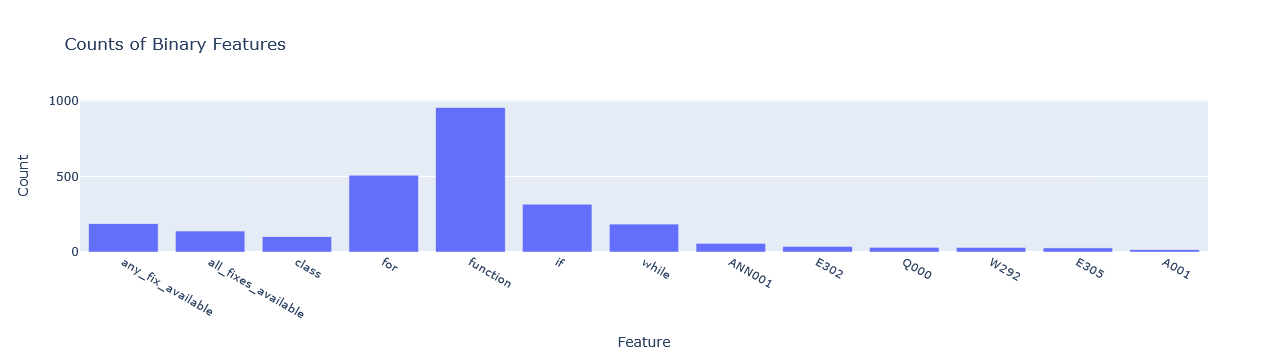

In [55]:
counts = rf_dataset_sim[[
    "any_fix_available",
    "all_fixes_available",
    "class",
    "for",
    "function",
    "if",
    "while",
    "ANN001",
    "E302",
    "Q000",
    "W292",
    "E305",
    "A001",
]].sum()

fig = go.Figure(go.Bar(x=counts.index, y=counts.values))
fig.update_layout(title='Counts of Binary Features', xaxis_title='Feature', yaxis_title='Count')
fig.show()

### Continous Features

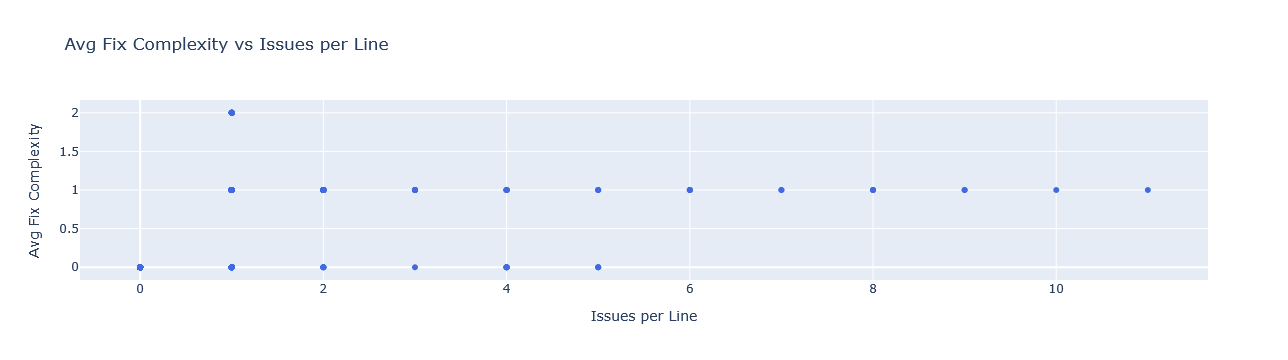

In [56]:
fig = go.Figure(go.Scatter(
    x=rf_dataset_sim['issues_per_line'], y=rf_dataset_sim['avg_fix_complexity'],
    mode='markers',
    marker=dict(color='royalblue'),
    name='Fix Complexity vs Issues/Line'
))
fig.update_layout(title='Avg Fix Complexity vs Issues per Line', xaxis_title='Issues per Line', yaxis_title='Avg Fix Complexity')
fig.show()

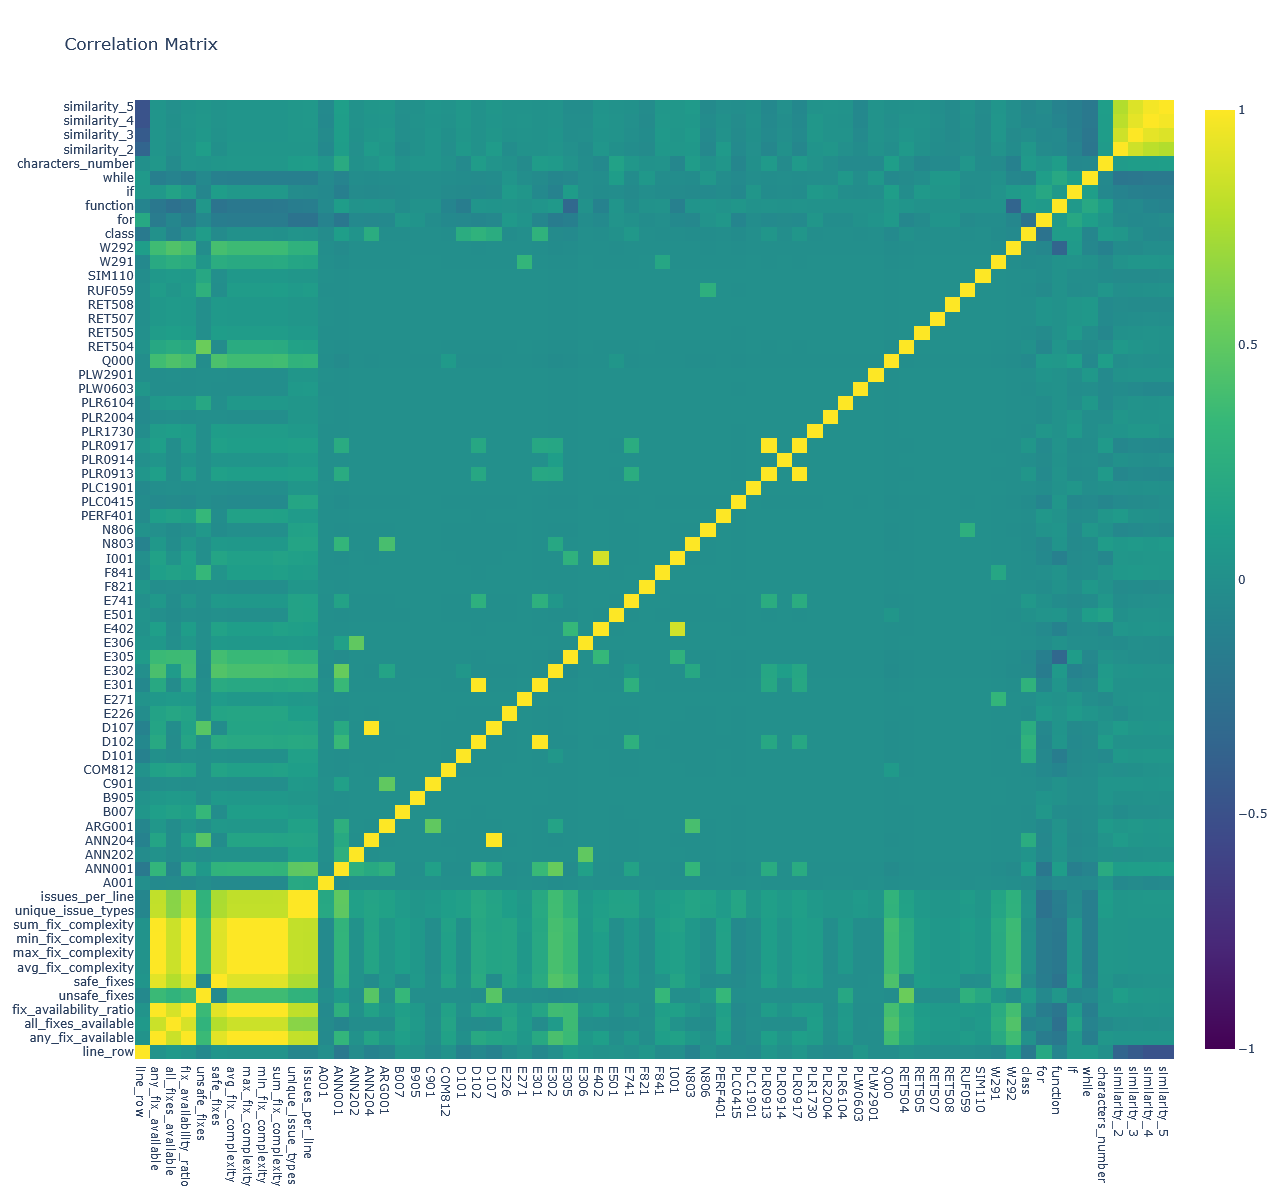

In [62]:
correlation = rf_dataset_sim.corr(method= 'spearman', numeric_only=True)
heatmap = go.Heatmap(
    z=correlation.values,
    x=correlation.columns,
    y=correlation.columns,
    colorscale='Viridis',
    zmin=-1, zmax=1
)
fig = go.Figure(data=heatmap)
fig.update_layout(title='Correlation Matrix', width=1200, height=1200)
fig.show()

In [59]:
correlation

,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,sum_fix_complexity,...,class,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5
line_row,1.000000,0.022575,0.072967,0.030353,-0.056050,0.043441,0.021782,0.021782,0.021782,0.019940,...,-0.178581,0.195629,-0.094544,0.060903,0.074773,0.001277,-0.354344,-0.424990,-0.480373,-0.484834
any_fix_available,0.022575,1.000000,0.841647,0.996975,0.352126,0.915130,0.998790,0.998790,0.998790,0.998029,...,0.005971,-0.165605,-0.199133,0.062588,-0.139737,0.052401,0.041513,0.038124,0.041036,0.036478
all_fixes_available,0.072967,0.841647,1.000000,0.880495,0.295248,0.772296,0.845403,0.845403,0.845403,0.844907,...,-0.104533,-0.080196,-0.256215,0.149001,-0.102721,-0.039681,-0.006940,-0.002224,0.002065,-0.003714
fix_availability_ratio,0.030353,0.996975,0.880495,1.000000,0.351156,0.912654,0.996446,0.996446,0.996446,0.995824,...,-0.010627,-0.156585,-0.211978,0.076071,-0.137201,0.039051,0.036562,0.033978,0.037273,0.032471
unsafe_fixes,-0.056050,0.352126,0.295248,0.351156,1.000000,-0.045561,0.373431,0.373431,0.373431,0.373347,...,0.094158,-0.055919,0.056063,-0.081844,-0.051640,0.033251,0.107795,0.066279,0.051603,0.047678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
characters_number,0.001277,0.052401,-0.039681,0.039051,0.033251,0.044895,0.052619,0.052619,0.052619,0.054541,...,0.079402,0.037395,0.100401,-0.061188,-0.056809,1.000000,0.085629,0.101005,0.106193,0.113559
similarity_2,-0.354344,0.041513,-0.006940,0.036562,0.107795,0.000929,0.044471,0.044471,0.044471,0.045969,...,0.057373,-0.041027,-0.058270,-0.103435,-0.209678,0.085629,1.000000,0.854891,0.796113,0.767253
similarity_3,-0.424990,0.038124,-0.002224,0.033978,0.066279,0.015866,0.039763,0.039763,0.039763,0.041498,...,-0.017463,-0.055367,-0.048216,-0.126651,-0.202460,0.101005,0.854891,1.000000,0.925052,0.898271
similarity_4,-0.480373,0.041036,0.002065,0.037273,0.051603,0.025094,0.042235,0.042235,0.042235,0.043601,...,-0.052892,-0.046963,-0.090694,-0.134857,-0.187859,0.106193,0.796113,0.925052,1.000000,0.971501


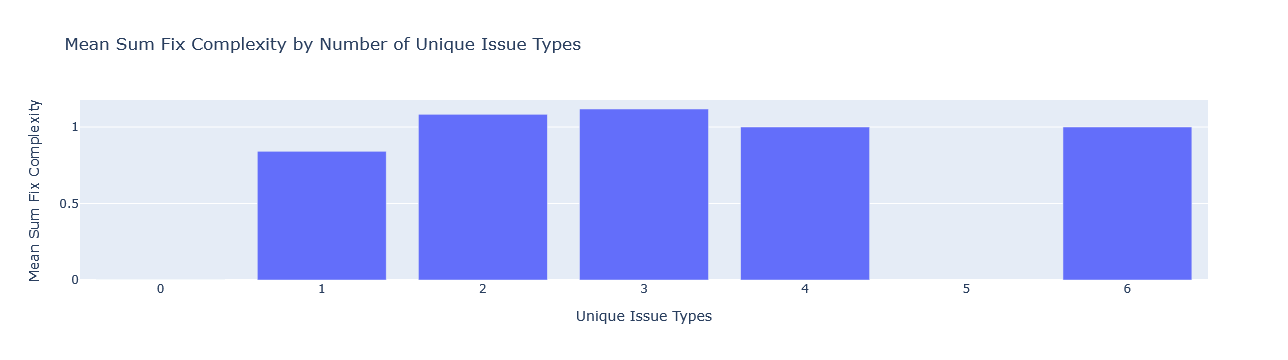

In [65]:
grouped = rf_dataset_sim.groupby('unique_issue_types')['sum_fix_complexity'].mean().reset_index()

fig = go.Figure(go.Bar(
    x=grouped['unique_issue_types'],
    y=grouped['sum_fix_complexity']
))
fig.update_layout(title='Mean Sum Fix Complexity by Number of Unique Issue Types',
                  xaxis_title='Unique Issue Types',
                  yaxis_title='Mean Sum Fix Complexity')
fig.show()

## Modeling

In [116]:
y = pd.read_csv('datasets/evaluation_python_solutions_1.csv')['good']
X = rf_dataset_sim.drop(columns=['title', 'similarity_2', 'similarity_3', 'similarity_4'])

In [117]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=0
)

In [118]:
param_dist = {
    'n_estimators': list(range(64, 129, 16)), 
    'min_samples_leaf': list(range(1, 21)),    
    'max_features': ['sqrt', 'log2', None]    
}

In [119]:
rf = RandomForestClassifier(random_state=0)
f1 = make_scorer(f1_score, average='binary', pos_label=1)

In [120]:
search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=30,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    scoring=f1,
    n_jobs=-1,
    random_state=0
)
search.fit(X_train, y_train)
y_pred = search.predict(X_test)
f1_test = f1_score(y_test, y_pred, pos_label=1)

print(f"Best Params: {search.best_params_}")
print(f"Test F1-score: {f1_test:.4f}")

Best Params: {'n_estimators': 112, 'min_samples_leaf': 18, 'max_features': 'log2'}
Test F1-score: 0.9057


                   feature  importance
0                 line_row    0.241560
64            similarity_5    0.179243
63       characters_number    0.149084
62                   while    0.059673
11         issues_per_line    0.058658
61                      if    0.036266
59                     for    0.035326
60                function    0.029905
3   fix_availability_ratio    0.026893
58                   class    0.026021



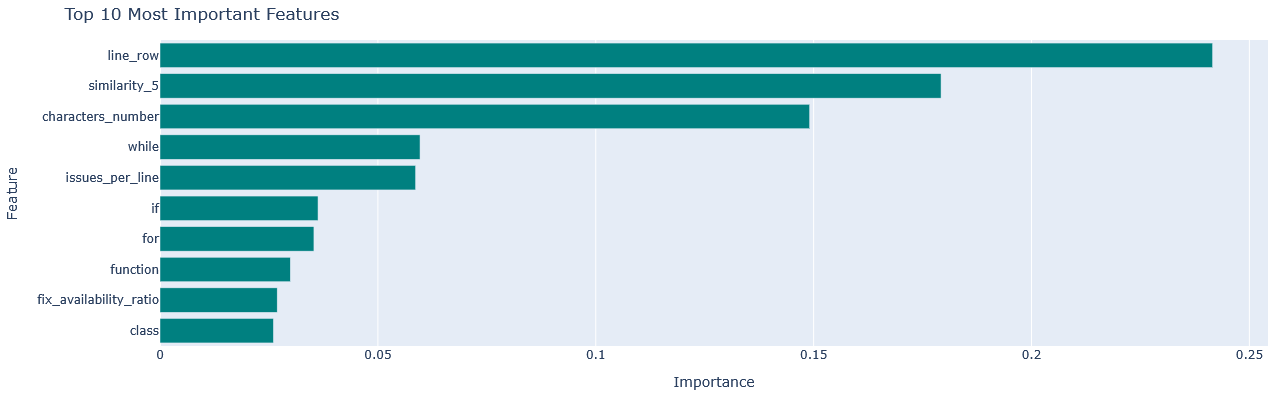

In [121]:
best_rf = search.best_estimator_

importances = best_rf.feature_importances_
feature_names = X.columns

feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(feature_importance_df.head(10))
print()

top_n = 10
top_features = feature_importance_df.head(top_n).sort_values(by='importance')

fig = go.Figure(go.Bar(
    x=top_features['importance'],
    y=top_features['feature'],
    orientation='h',
    marker=dict(color='teal')
))

fig.update_layout(
    title=f"Top {top_n} Most Important Features",
    xaxis_title="Importance",
    yaxis_title="Feature",
    height=400,
    margin=dict(l=100, r=20, t=40, b=40)
)

fig.show()

In [122]:
all_probabilities = pd.read_csv('datasets/all_probabilities.csv')

In [123]:
proba = best_rf.predict_proba(X)

proba_class_1 = proba[:, 1]

all_probabilities['rf_with_sim'] = proba_class_1
all_probabilities.head()

,Unnamed: 0.1,Unnamed: 0,title,line_number,line_text,token_prob,similarity_2,similarity_3,similarity_4,similarity_5,rf_with_sim
0,0,0,Sports Rank,1,def read_input():\n,0.667149,0.971578,0.945252,0.946623,0.945271,0.819108
1,1,1,Sports Rank,2,import sys\n,0.972428,1.000000,0.887545,0.922889,0.940561,0.814571
2,2,2,Sports Rank,3,input = sys.stdin.read\n,0.992203,0.872590,0.833801,0.862679,0.879646,0.805567
3,3,3,Sports Rank,4,data = input().split()\n,0.992855,0.899708,0.814728,0.864639,0.822439,0.805729
4,4,4,Sports Rank,5,index = 0\n,0.939398,0.884853,0.914327,0.931024,0.936494,0.804211


In [124]:
all_probabilities.to_csv('datasets/all_probabilities.csv')